# Phân tích kết quả benchmark (chạy trong CÙNG session Colab với `googleCollab_bench_all.ipynb`)

Notebook này đọc `raw/*.json` trên đĩa tạm `/content/work/benchmark_results/raw/`, nên **chỉ dùng được khi runtime chưa bị ngắt** sau khi benchmark chạy xong. Nếu runtime đã reset thì `raw` mất; khi đó chỉ còn `summary.csv` và `predictions.csv` trên Drive.

Không ghi thêm file nào lên Drive, chỉ hiển thị bảng và biểu đồ.

**Chạy trên máy cá nhân:** giải nén zip tải từ Drive sao cho có `googleColab/benchmark_results/raw/*.json`, rồi mở notebook này trong thư mục `googleColab/`.

In [7]:
import os, sys
# if os.path.isdir("/content"):                  # Colab: cùng session với googleCollab_bench_all.ipynb
#     WORK = "/content/work"
#     OUT_DIR = "/content/drive/MyDrive/faster_whisper_bench_results"
#     os.chdir(WORK)
# else:                                          # máy cá nhân: giải nén zip kết quả vào ./benchmark_results (raw/, summary.csv, predictions.csv)
WORK = os.getcwd()
OUT_DIR = os.path.join(WORK, "benchmark_results")
sys.path.insert(0, WORK)
from bench_common import *
pd.set_option("display.max_columns", None); pd.set_option("display.width", 250)

n_raw = len(list(RAW_DIR.glob("*.json")))
print(f"{n_raw} file raw trong {RAW_DIR}")
assert n_raw > 0, "Không có raw: runtime đã bị reset hoặc benchmark chưa chạy. Dùng summary.csv/predictions.csv trên Drive."
df = load_results()
show_status(df)

39 file raw trong d:\Benchmark\benchmark_results\raw
status                        ok
model    device compute_type    
base     cpu    int8           3
         cuda   float16        3
                int8           3
large-v3 cuda   float16        3
                int8           3
medium   cuda   float16        3
                int8           3
small    cpu    int8           3
         cuda   float16        3
                int8           3
tiny     cpu    int8           3
         cuda   float16        3
                int8           3


In [8]:
summary = summarize(df)
cols = ["model", "device", "compute_type", "n_ok", "rtf_mean", "wer_mean", "cer_mean", "model_load_sec_mean",
        "ram_net_peak_mb_mean", "vram_peak_mb_mean", "vram_net_peak_mb_mean", "gpu_util_avg_eval_pct_mean",
        "cpu_net_pct_eval_mean"]
summary[[c for c in cols if c in summary.columns]].round(3)

,model,device,compute_type,n_ok,rtf_mean,wer_mean,cer_mean,model_load_sec_mean,ram_net_peak_mb_mean,vram_peak_mb_mean,vram_net_peak_mb_mean,gpu_util_avg_eval_pct_mean,cpu_net_pct_eval_mean
0,tiny,cpu,int8,3,0.262,0.536,0.287,0.732,217.260,NaN,NaN,NaN,43.688
1,base,cpu,int8,3,0.487,0.371,0.184,0.942,306.946,NaN,NaN,NaN,61.902
2,small,cpu,int8,3,1.468,0.213,0.098,1.831,718.109,NaN,NaN,NaN,55.983
3,tiny,cuda,float16,3,0.046,0.585,0.345,0.748,527.895,726.188,276.0,32.386,89.662
4,base,cuda,float16,3,0.048,0.370,0.182,0.806,578.771,822.188,372.0,34.677,86.817
5,small,cuda,float16,3,0.064,0.222,0.101,1.150,558.387,1206.188,756.0,62.968,76.259
6,medium,cuda,float16,3,0.127,0.150,0.077,2.055,1512.406,2326.188,1876.0,86.211,63.904
7,large-v3,cuda,float16,3,0.206,0.113,0.057,3.569,2990.816,3926.188,3476.0,92.661,58.484
8,tiny,cuda,int8,3,0.048,0.615,0.368,0.885,523.998,694.188,244.0,33.342,87.693
9,base,cuda,int8,3,0.050,0.371,0.183,1.020,573.575,726.188,276.0,35.614,84.888


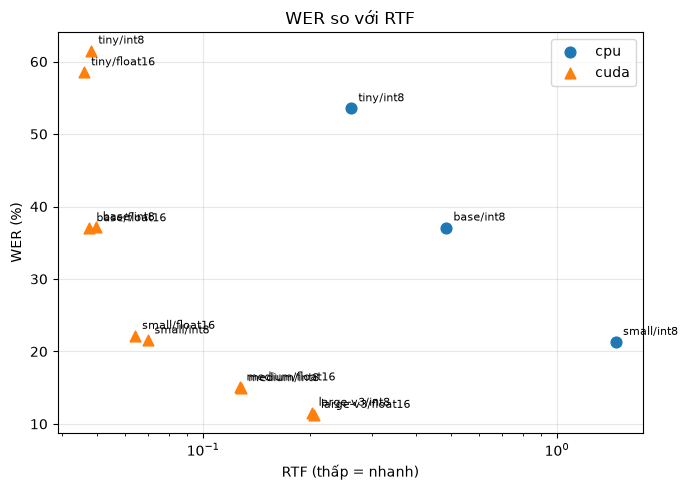

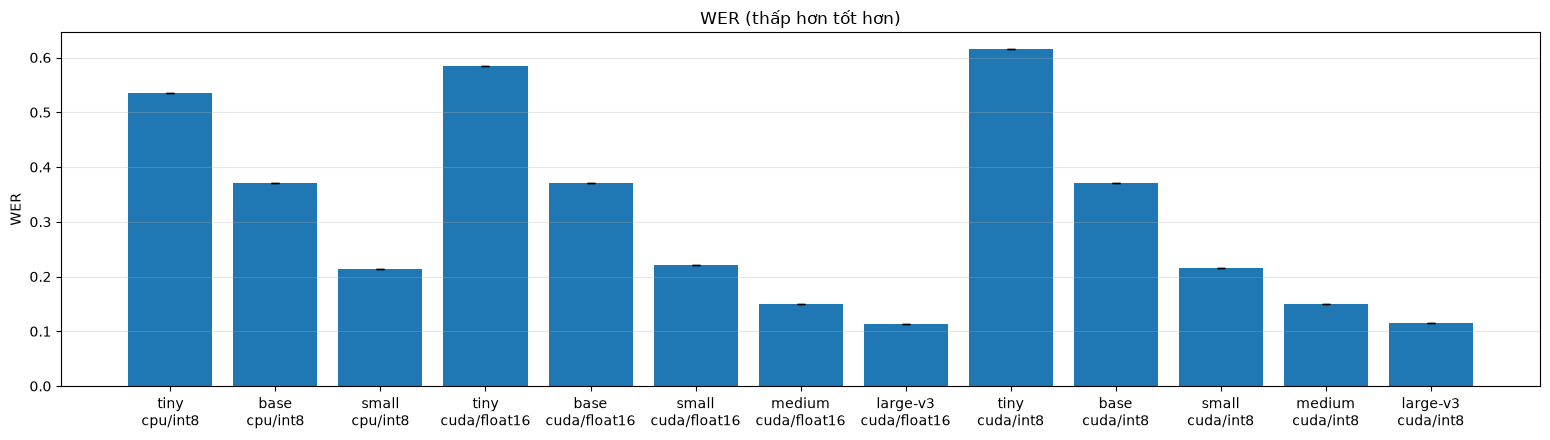

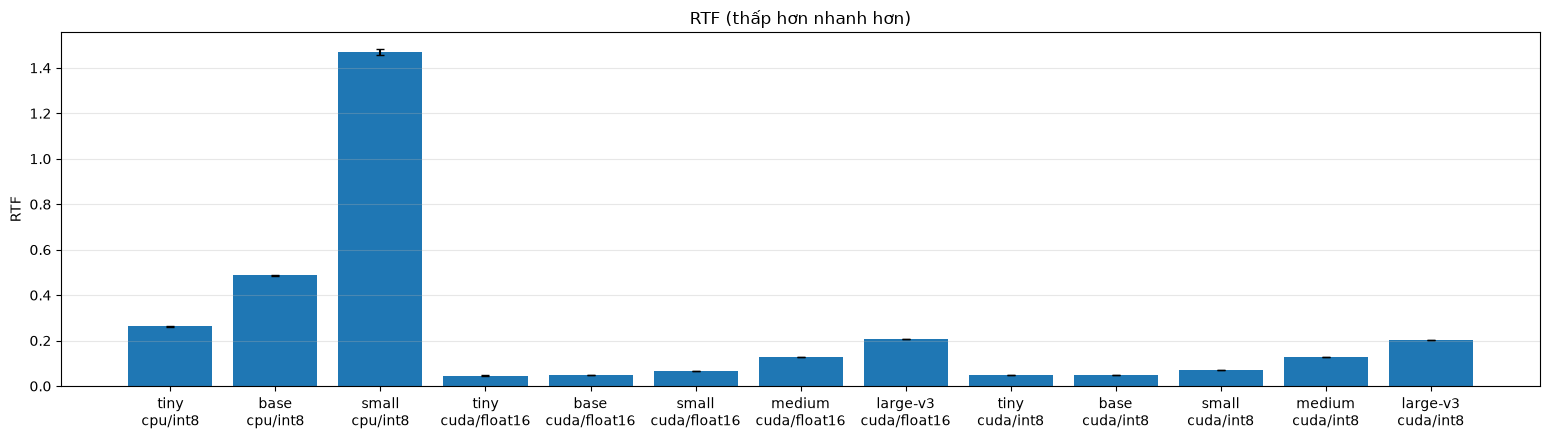

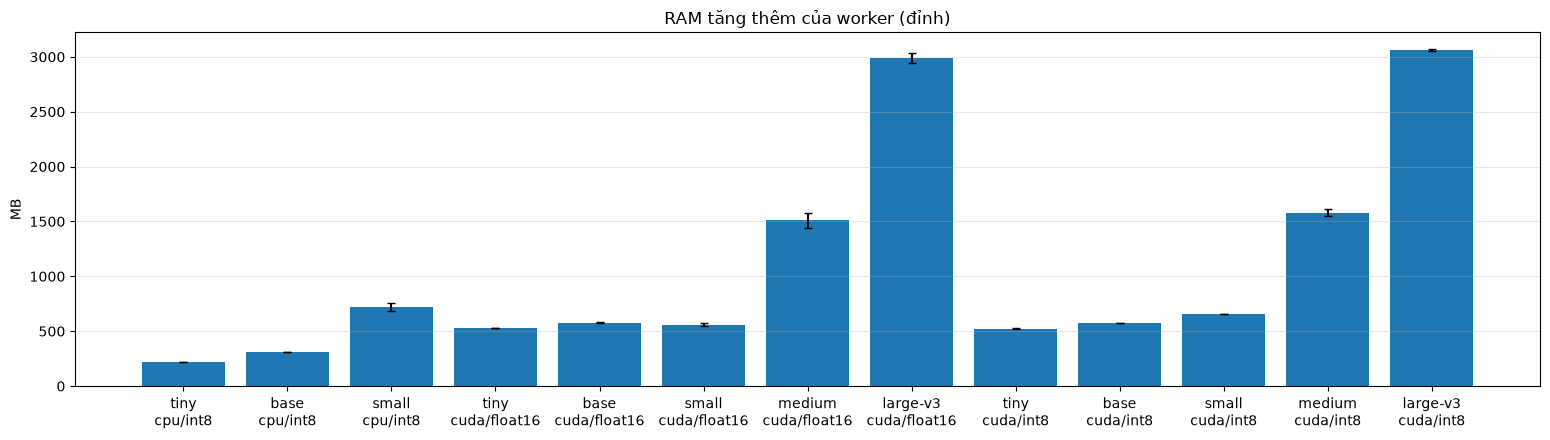

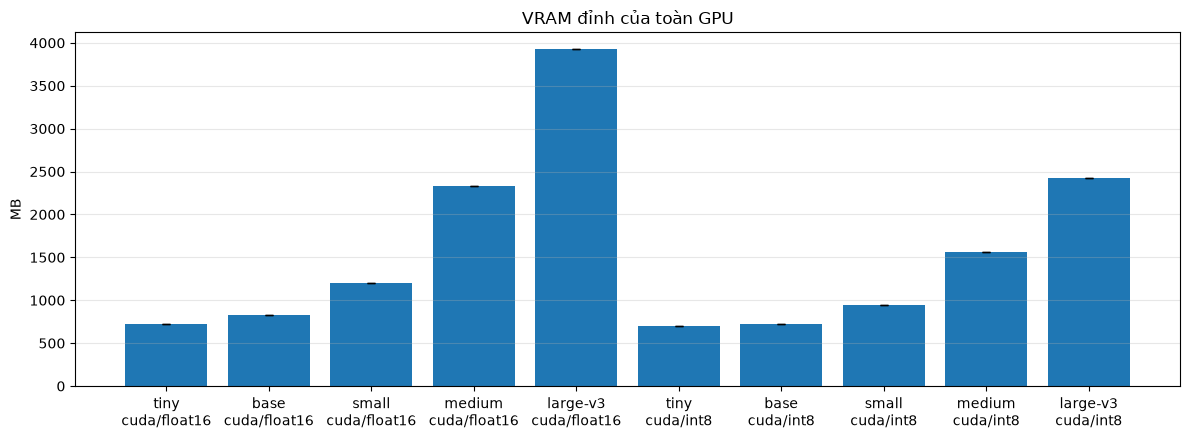

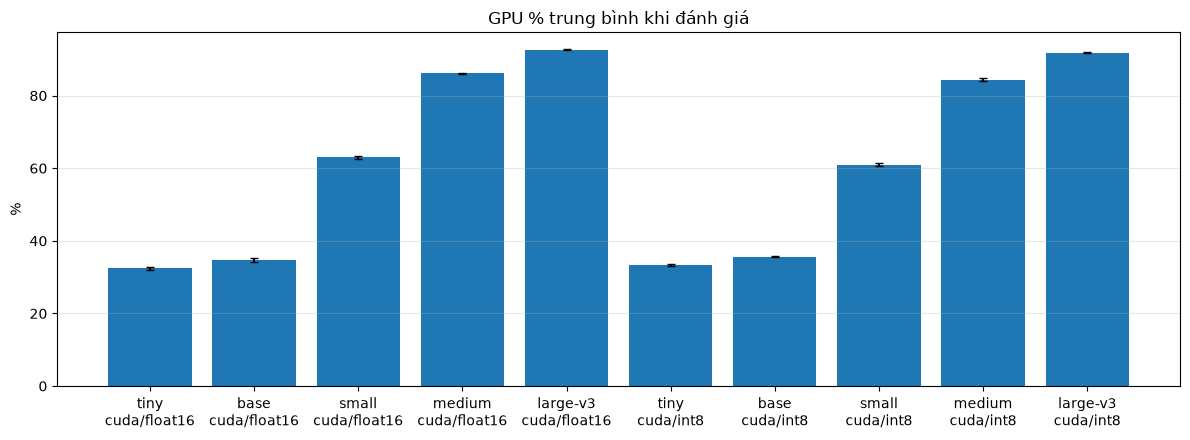

In [9]:
plot_wer_vs_rtf(summary)
plot_bar(summary, "wer", "WER", "WER (thấp hơn tốt hơn)")
plot_bar(summary, "rtf", "RTF", "RTF (thấp hơn nhanh hơn)")
plot_bar(summary, "ram_net_peak_mb", "MB", "RAM tăng thêm của worker (đỉnh)")
plot_bar(summary, "vram_peak_mb", "MB", "VRAM đỉnh của toàn GPU")
plot_bar(summary, "gpu_util_avg_eval_pct", "%", "GPU % trung bình khi đánh giá")

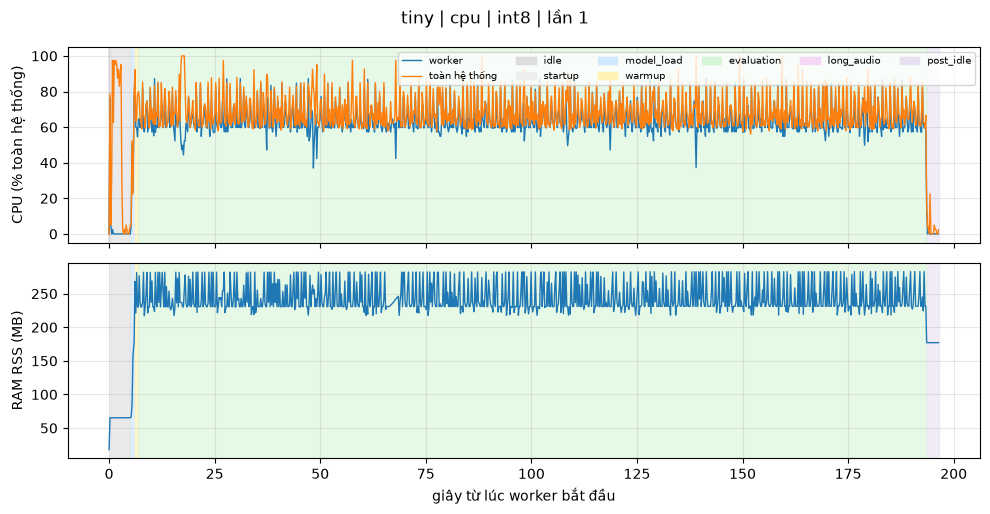

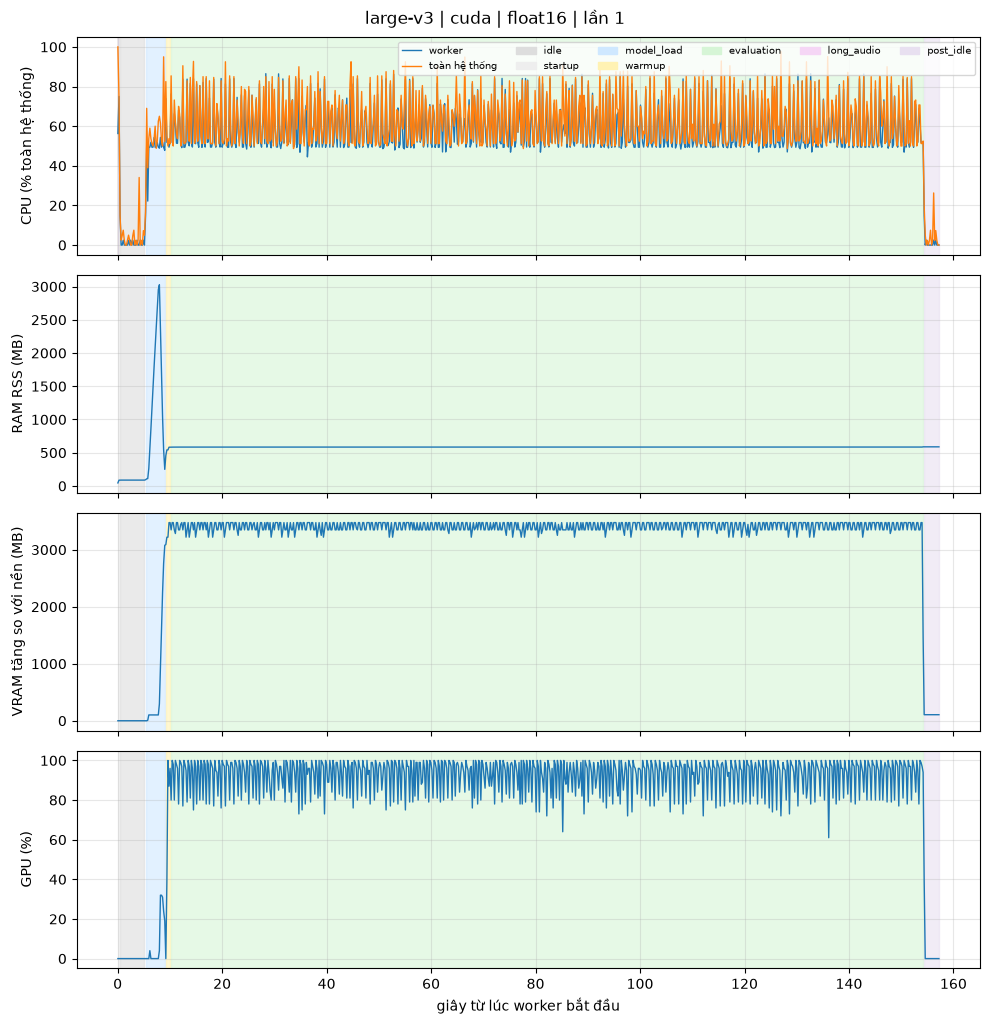

In [10]:
# Biến thiên theo thời gian của một cấu hình (CPU worker vs CPU hệ thống, RAM, VRAM, GPU %)
plot_timeseries(df, "tiny", "cpu", "int8", repeat=1)
plot_timeseries(df, "large-v3", "cuda", "float16", repeat=1)

In [11]:
# Lỗi theo từng câu: WER mỗi câu, số câu đúng hoàn toàn, phân bố mức lỗi
import re, unicodedata
from jiwer import wer as _wer

def norm(t):                                   # giống bench_worker.normalize_text
    t = unicodedata.normalize("NFC", str(t or "")).lower()
    t = re.sub(r"[^\w\s]", " ", t).replace("_", " ")
    return " ".join(t.split())

pred = export_predictions(df)                  # ghi predictions.csv vào đĩa tạm (không đụng Drive)
# Các lần lặp chỉ để đo độ lệch chuẩn tốc độ/tài nguyên; temperature=0 nên văn bản giống hệt nhau -> giữ 1 lần/câu
pred = (pred.sort_values("repeat")
            .drop_duplicates(["model", "device", "compute_type", "audio"]).reset_index(drop=True))
pred["sent_wer"] = [_wer(norm(r), norm(h)) if norm(r) else None for r, h in zip(pred.reference, pred.hypothesis)]
pred["bucket"] = pd.cut(pred.sent_wer, [-1, 0, .25, .5, 1, 99],
                        labels=["đúng hết", "<=25%", "25-50%", "50-100%", ">100%"])
dist = pred.groupby(["model", "device", "compute_type", "bucket"], observed=False).size().unstack(fill_value=0)
dist["tổng câu"] = dist.sum(axis=1)
dist

bucket                        đúng hết  <=25%  25-50%  50-100%  >100%  tổng câu
model    device compute_type                                                   
base     cpu    int8                 8     55      86       50      1       200
         cuda   float16              9     57      82       51      1       200
                int8                 8     54      87       50      1       200
large-v3 cuda   float16             93     76      22        9      0       200
                int8                91     78      19       12      0       200
medium   cuda   float16             68     88      30       14      0       200
                int8                64     96      29       11      0       200
small    cpu    int8                32    104      45       19      0       200
         cuda   float16             35     99      44       22      0       200
                int8                30    106      42       22      0       200
tiny     cpu    int8                 5     27      71       90      7       200
         cuda   float16              5     29      74       88      4       200
                int8                 3     28      80       83      6       200

In [13]:
# So sánh hai cấu hình trên cùng một model: câu nào dịch khác nhau (kiểm tra lặp từ, ảo giác...)
def compare(model, a, b, n=15):
    """a, b = (device, compute_type). In n câu có hypothesis khác nhau nhiều nhất."""
    pa = pred[(pred.model == model) & (pred.device == a[0]) & (pred.compute_type == a[1])].set_index("audio")
    pb = pred[(pred.model == model) & (pred.device == b[0]) & (pred.compute_type == b[1])].set_index("audio")
    j = pa[["reference", "hypothesis", "sent_wer"]].join(pb[["hypothesis", "sent_wer"]], lsuffix="_A", rsuffix="_B", how="inner")
    j["khác"] = j.hypothesis_A.map(norm) != j.hypothesis_B.map(norm)
    j["chênh_wer"] = (j.sent_wer_A - j.sent_wer_B).abs()
    print(f"{model}: {a} vs {b} | {int(j['khác'].sum())}/{len(j)} câu khác nhau | "
          f"WER trung bình câu A={j.sent_wer_A.mean():.3f}, B={j.sent_wer_B.mean():.3f}")
    return j[j["khác"]].sort_values("chênh_wer", ascending=False).head(n).reset_index(drop=True)   # bỏ cột audio


In [14]:
compare("tiny", ("cuda", "float16"), ("cuda", "int8"))

tiny: ('cuda', 'float16') vs ('cuda', 'int8') | 115/200 câu khác nhau | WER trung bình câu A=0.681, B=0.750


,reference,hypothesis_A,sent_wer_A,hypothesis_B,sent_wer_B,khác,chênh_wer
0,HAI MƯƠI SÁU HAI MƯƠI BẢY,"Hẹn gặp, hẹn gặp, hẹn gặp.",1.000000,"Hôm nay rau, hôm nay bây giờ, hôm nay bây giờ,...",21.166667,True,20.166667
1,CON CHÓ LỦI THỦI ĐI THEO CHỦ NÓ,Còn cho lửa thửa thửa thửa thửa thửa thửa thửa...,9.500000,Còn chá lửa thửa thửa thửa thửa thửa thửa thửa...,1.375000,True,8.125000
2,KHIẾN CẢ HAI PHẢI GIẬN HỜN VÔ LÝ,khiến cá hai phải dẫn hình hồn ngô lý.,0.625000,khiến cá hai phải dẫn hình hình hình hình hình...,1.500000,True,0.875000
3,NĂM MƯƠI NĂM MƯƠI MỐT,"Nam mươi, Nam mươi mốt",0.400000,"Nam mưa, Nam mưa mớp",1.000000,True,0.600000
4,BÀ NÓI,Bà nói,0.000000,Bà Nội,0.500000,True,0.500000
5,NƯỚC CHẢY QUÁ MẠNH,Nước kẻ quá mạnh,0.250000,Nước kể qua mình,0.750000,True,0.500000
6,NĂM MƯƠI NĂM MƯƠI MỐT,Nằm mươi nằm mươi mươi mươi mươi mươi mươi mươ...,14.600000,Năm mươi năm mươi mươi mươi mươi mươi mươi mươ...,14.200000,True,0.400000
7,NHẰM TẠO RA SỰ HẤP DẪN,nhằm tạo ra sử hấp dẫn,0.166667,Nhanh đảo ra sử hấp dẫn,0.500000,True,0.333333
8,MÀ DUNG DĂNG NHÉ CẦM TAY ĐẤT TRỜI,"Mà dung dân nghe, tầm ca lất trời.",0.625000,"Mà dung dân nghe, cầm tay lất trời.",0.375000,True,0.250000
9,LUÔN ỔN ĐỊNH VÀ CÁC XE TRẤU KHÁ NẶNG,Lung ủng đánh và các xe trấu khán Ấn Ấn,0.666667,luôn ủng đánh và các xe trấu khán Ấn,0.444444,True,0.222222


In [15]:
compare("large-v3", ("cuda", "float16"), ("cuda", "int8"))

large-v3: ('cuda', 'float16') vs ('cuda', 'int8') | 17/200 câu khác nhau | WER trung bình câu A=0.132, B=0.138


,reference,hypothesis_A,sent_wer_A,hypothesis_B,sent_wer_B,khác,chênh_wer
0,NĂM MƯƠI NĂM MƯƠI MỐT,Năm mươi năm mươi mốt,0.000000,50-51,1.000000,True,1.000000
1,NHƯNG OÁI ĂM THAY,Nhưng oái âm thai,0.500000,Nhưng ói âm thai,0.750000,True,0.250000
2,SƯƠNG MÙ ĐÃ ĐỌNG THÀNH NHỮNG HẠT GIÁ BĂNG,Sương mù đã động thành những hạt giáp ăn.,0.333333,Sương mù đã động thành những hạt giá băng.,0.111111,True,0.222222
3,ĐÔI BÀN TAY EM KHÔNG ĐƯỢC MỀM MẠI VÀ NÕN NÀ,Đôi bàn tay em không được mìm mãi và nón nà,0.272727,Đôi bàn tay em không được mềm mại và nón nà,0.090909,True,0.181818
4,CHÍU CHÍT GỢI TÌNH MẸ CON SUM HỌP,Chiếu chít gọi tình mẹ con xâm hợp,0.500000,Chiếu chích gọi tình mẹ con xâm hợp,0.625000,True,0.125000
5,KHI BỊ CÔNG AN THỘP CỔ KHẨN CẤP,khi bị công an hợp cổ hẳn cấp.,0.250000,thì bị công an hợp cổ hẳn cấp.,0.375000,True,0.125000
6,NHƯNG MỨC ÁN TỬ HÌNH ĐỐI VỚI CÁC BỊ CÁO LÀ TƯƠ...,nhưng mức án tử hình đối với các bị cáo là tươ...,0.076923,nhưng mức án tử hình đối với các bị cáo là tươ...,0.000000,True,0.076923
7,NGƯỜI ANH SAU ĐÓ ĐƯỢC PHÉP THẦU XÂY KÊNH NÀY N...,Người Anh sau đó được phép thầu xây kênh này n...,0.000000,Người Anh sau đó được phép thầu xoay kênh này ...,0.071429,True,0.071429
8,NGHE TIẾNG XÌNH XỊCH XA XA THÌ ĐOÁN TRÚNG PHÓC...,Nghe tiếng xình xịch xa xa thì đoán trúng phóc...,0.000000,Nghe tiếng xình xịt xa xa thì đoán trúng phóc ...,0.071429,True,0.071429
9,UNG THƯ TỪ MỘT CƠ QUAN KHÁC DI CĂN VÀO HỆ THỐN...,Ông thư từ một cơ quan khác di căn vào hệ thốn...,0.066667,Ông thư từ một cơ quan khác di can vào hệ thốn...,0.133333,True,0.066667
